# Heart Disease Classification Workflow

**Week 4 – Machine Learning Assignment**

## Part 1 – Data Understanding

In this assignment, I will use the Cleveland Heart Disease dataset
to compare two machine-learning models. I will examine the data,
train the models, compare their results, and explain what I found.

In [1]:
import pandas as pd

# Load the Cleveland Heart Disease dataset
df = pd.read_csv("Cleveland-303-10.csv")

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display the first five rows
display(df.head())

Dataset shape: (303, 11)


,age,sex,chest pain type,resting bp s,cholesterol,resting ecg,max heart rate,exercise angina,oldpeak,ST slope,target
0,63,1,1,145,233,2,150,0,2.3,3,0
1,67,1,4,160,286,2,108,1,1.5,2,1
2,67,1,4,120,229,2,129,1,2.6,2,1
3,37,1,3,130,250,0,187,0,3.5,3,0
4,41,0,2,130,204,2,172,0,1.4,1,0


### Identifying Features and Target

The dataset contains information that can be used to classify
heart disease cases. The feature columns contain the information
the models will learn from, while the target column contains
the classification the models will try to predict.

In [2]:
# Identify the target column
target_column = "target"

# Separate the features and target
X = df.drop(columns=[target_column])
y = df[target_column]

# Display the feature columns
print("Feature columns:")
print(X.columns.tolist())

# Display the target column
print("\nTarget column:", target_column)

# Display the number of features
print("\nNumber of features:", X.shape[1])

Feature columns:
['age', 'sex', 'chest pain type', 'resting bp s', 'cholesterol', 'resting ecg', 'max heart rate', 'exercise angina', 'oldpeak', 'ST slope']

Target column: target

Number of features: 10


### Class Balance

In this section, I will examine how many records belong to each
target class and calculate their percentages. This will help
determine whether the dataset is balanced or whether one class
appears more frequently than the other.

In [3]:
# Count the number of records in each target class
class_counts = y.value_counts().sort_index()

# Calculate the percentage of each target class
class_percentages = y.value_counts(normalize=True).sort_index() * 100

# Combine the results into a table
class_balance = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

# Display the results
print("Target Class Distribution:")
display(class_balance)

Target Class Distribution:


,Count,Percentage
target,,
0,164,54.13
1,139,45.87


The dataset appears to be fairly balanced between the two target classes. Class 0 represents about 54% of the records, while Class 1 represents about 46%. Since the percentages are relatively close, neither class is significantly more common than the other.

### Checking for Missing Values

In this section, I will check each column for missing values.
Missing data can affect machine-learning models, so it is
important to identify any missing values before training.

In [4]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Display missing values for every column
print("Missing Values by Column:")
display(missing_values.to_frame(name="Missing Values"))

# Display the total number of missing values
print("\nTotal missing values:", missing_values.sum())

Missing Values by Column:


,Missing Values
age,0
sex,0
chest pain type,0
resting bp s,0
cholesterol,0
resting ecg,0
max heart rate,0
exercise angina,0
oldpeak,0
ST slope,0



Total missing values: 0


The dataset does not contain any missing values, so no records need to be removed. Even though there are no missing values, I will still include missing-value handling in the machine-learning pipelines as required by the assignment.

## Part 2 – Split and Baseline

### Splitting the Dataset

I will divide the dataset into 80% training data and 20% testing
data. The training data will be used to build the models, while
the testing data will be kept separate to evaluate their performance.

I will also use stratification to keep the proportions of the
two target classes similar in both groups.

In [5]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing portions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display training and testing shapes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (242, 10)
Testing features: (61, 10)
Training targets: (242,)
Testing targets: (61,)


In [6]:
# Compare class counts and percentages in each dataset
train_balance = pd.DataFrame({
    "Count": y_train.value_counts().sort_index(),
    "Percentage": (
        y_train.value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

test_balance = pd.DataFrame({
    "Count": y_test.value_counts().sort_index(),
    "Percentage": (
        y_test.value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

print("Training Class Distribution:")
display(train_balance)

print("Testing Class Distribution:")
display(test_balance)

Training Class Distribution:


,Count,Percentage
target,,
0,131,54.13
1,111,45.87


Testing Class Distribution:


,Count,Percentage
target,,
0,33,54.1
1,28,45.9


After splitting the dataset, the training and testing groups have similar proportions of class 0 and class 1. This is because I used stratification when dividing the data. It helps make sure both classes are represented fairly in the test set.

### Baseline Model - DummyClassifier

Before training the machine-learning models, I will create a
simple baseline using DummyClassifier.

The baseline always predicts the most common target class
from the training data. This gives me a starting point for
comparing the performance of Logistic Regression and Random Forest.

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Create a baseline model that always predicts the most common class
baseline_model = DummyClassifier(strategy="most_frequent")

# Train the baseline using the training data
baseline_model.fit(X_train, y_train)

# Make predictions using the held-out test data
baseline_predictions = baseline_model.predict(X_test)

# Calculate baseline accuracy
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

# Display results
print("Baseline Model: DummyClassifier")
print(f"Baseline Test Accuracy: {baseline_accuracy:.2%}")

Baseline Model: DummyClassifier
Baseline Test Accuracy: 54.10%


The DummyClassifier achieved a test accuracy of approximately 54%. This model always predicts the most common class instead of learning patterns from the data. I will use this result as a baseline to see whether Logistic Regression and Random Forest can perform better.

## Part 3 – Leakage-Safe Preparation and Models

### Identifying Numeric and Categorical Features

Before training the models, I will separate the features into
numeric and categorical columns.

Numeric features contain measurements, while categorical
features represent different groups or categories.

Some categorical features are stored as numbers in this dataset,
so I will identify them manually to make sure they are handled
correctly during preprocessing.

In [8]:
# Identify numeric features
numeric_features = [
    "age",
    "resting bp s",
    "cholesterol",
    "max heart rate",
    "oldpeak"
]

# Identify categorical features
categorical_features = [
    "sex",
    "chest pain type",
    "resting ecg",
    "exercise angina",
    "ST slope"
]

# Display the feature groups
print("Numeric Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

# Verify every feature is included exactly once
assert set(numeric_features).isdisjoint(categorical_features)
assert set(numeric_features + categorical_features) == set(X.columns)

print("\nAll features accounted for!")

Numeric Features:
['age', 'resting bp s', 'cholesterol', 'max heart rate', 'oldpeak']

Categorical Features:
['sex', 'chest pain type', 'resting ecg', 'exercise angina', 'ST slope']

Number of numeric features: 5
Number of categorical features: 5

All features accounted for!


### Building the Preprocessing Pipelines

Before training the models, I will create preprocessing steps
for the numeric and categorical features.

Numeric features will have missing values filled with the median
and then be scaled using StandardScaler.

Categorical features will have missing values filled with the
most frequent value and then be converted using OneHotEncoder.

These preprocessing steps will be included inside the model
pipelines so they are learned only from the training data.
This helps prevent data leakage.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Preprocessing for numeric features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numeric and categorical preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


### Model A - Logistic Regression

The first model I will train is Logistic Regression.

Logistic Regression is a classification model that estimates the
probability of a record belonging to a particular class.

I will combine it with the preprocessing pipeline so that
missing-value handling, scaling, and encoding are learned
from the training data only.

In [10]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression pipeline
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model using only the training data
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### Model B - Random Forest

The second model I will train is Random Forest.

Random Forest is a classification model that combines predictions
from multiple decision trees.

I will use 200 decision trees and set random_state=42 so the
results are reproducible.

Like Logistic Regression, Random Forest will use a preprocessing
pipeline that is fitted only on the training data.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

# Create the Random Forest pipeline
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

# Train the model using only the training data
random_forest_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## Part 4 – Model Evaluation

### Comparing Model Performance

Now that both models have been trained, I will evaluate them
using the same held-out test dataset.

I will compare accuracy, precision, recall, and F1 scores
to see how well each model performs.

Accuracy shows overall performance, while precision and
recall help explain the different types of classification errors.

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Make predictions using the held-out test data
logistic_predictions = logistic_pipeline.predict(X_test)
forest_predictions = random_forest_pipeline.predict(X_test)

# Calculate performance metrics for both models
results = []

for name, predictions in [
    ("Logistic Regression", logistic_predictions),
    ("Random Forest", forest_predictions)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

# Create a comparison table
results_df = pd.DataFrame(results)

# Display results as percentages
display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,88.52%,83.87%,92.86%,88.14%
1,Random Forest,85.25%,80.65%,89.29%,84.75%


I evaluated both models using the same test dataset and compared their accuracy, precision, recall, and F1 scores. I will focus primarily on recall because I want to compare how often each model misses actual Class 1 records. I will also consider the other metrics to understand the tradeoffs between the two models.

### Confusion Matrices

A confusion matrix shows how many predictions a model gets
correct and how many it gets wrong.

I will create a confusion matrix for Logistic Regression and
Random Forest to compare their classification errors.

I will pay particular attention to false negatives because
my main evaluation priority is recall for Class 1.

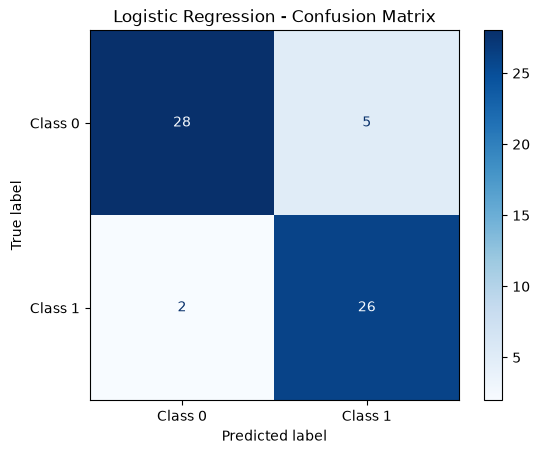

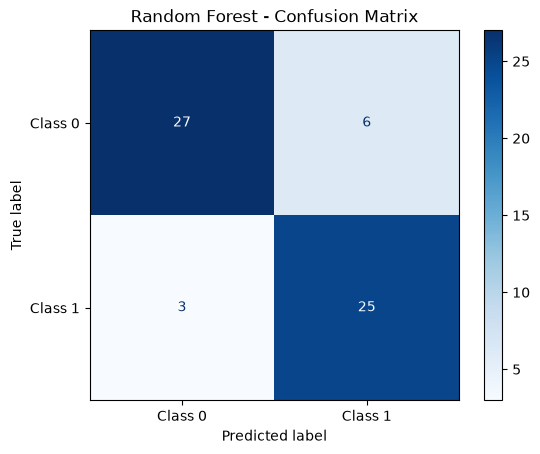

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create confusion matrix for Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    labels=[0, 1],
    display_labels=["Class 0", "Class 1"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# Create confusion matrix for Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test,
    forest_predictions,
    labels=[0, 1],
    display_labels=["Class 0", "Class 1"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

The confusion matrices show how many predictions each model got right or wrong. I am focusing on false negatives because these are records that actually belong to Class 1 but were predicted as Class 0.

I will compare the number of false negatives for both models to see which one performs better for my chosen error priority.

### Checking for Overfitting

Overfitting happens when a model learns the training data too
closely and does not perform as well on new data.

To check for possible overfitting, I will compare the training
accuracy and testing accuracy for both models.

A large difference between the two scores may indicate that
a model is overfitting.

In [14]:
# Compare training and testing accuracy for both models
overfitting_results = []

for name, model in [
    ("Logistic Regression", logistic_pipeline),
    ("Random Forest", random_forest_pipeline)
]:
    # Calculate accuracy on training and testing data
    train_accuracy = model.score(X_train, y_train)
    test_accuracy = model.score(X_test, y_test)

    overfitting_results.append({
        "Model": name,
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy,
        "Difference": train_accuracy - test_accuracy
    })

# Create a comparison table
overfitting_df = pd.DataFrame(overfitting_results)

# Display the results as percentages
display(
    overfitting_df.style.format({
        "Training Accuracy": "{:.2%}",
        "Testing Accuracy": "{:.2%}",
        "Difference": "{:.2%}"
    })
)

,Model,Training Accuracy,Testing Accuracy,Difference
0,Logistic Regression,79.75%,88.52%,-8.77%
1,Random Forest,100.00%,85.25%,14.75%


I compared the training and testing accuracy for both models to check for possible overfitting.

A model that performs much better on the training data than on the testing data may be learning patterns that do not generalize well. I will use the differences between these scores to help evaluate how well each model performs on new data.

## Part 5 – Model Interpretation and Conclusion

### Interpreting Logistic Regression

In this section, I will examine the Logistic Regression model
to identify which features have the strongest associations
with its predictions.

I will look at the five features with the largest coefficient
magnitudes. These coefficients show which prepared features
have the strongest influence on the model's predictions.

These relationships do not prove that a feature causes
heart disease.

In [15]:
import numpy as np

# Get the fitted preprocessing pipeline
fitted_preprocessor = logistic_pipeline.named_steps["preprocessor"]

# Get the prepared feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Get the Logistic Regression coefficients
coefficients = logistic_pipeline.named_steps["classifier"].coef_[0]

# Create a table of feature coefficients
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute Coefficient": np.abs(coefficients)
})

# Sort by largest absolute coefficient
feature_importance = feature_importance.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

# Display the five strongest features
print("Top 5 Logistic Regression Features:")
display(feature_importance.head(5))

Top 5 Logistic Regression Features:


,Feature,Coefficient,Absolute Coefficient
10,cat__chest pain type_4,1.225471,1.225471
5,cat__sex_0,-0.920126,0.920126
6,cat__sex_1,0.919333,0.919333
7,cat__chest pain type_1,-0.668393,0.668393
17,cat__ST slope_2,0.562697,0.562697


The Logistic Regression model identified several features that were strongly associated with its predictions. I examined the five features with the largest coefficient magnitudes to see which ones had the strongest influence on the model.

Positive coefficients were associated with predictions toward Class 1, while negative coefficients were associated with predictions toward Class 0. These results show patterns the model learned from the training data, but they do not mean those features cause heart disease.

### Final Conclusion

For this assignment, I trained and compared Logistic Regression and Random Forest using the Cleveland Heart Disease dataset. Both models used preprocessing pipelines to prepare the data without allowing information from the test set to leak into training.

**Model Comparison**

My main evaluation priority was recall because I wanted to minimize the number of actual Class 1 records incorrectly predicted as Class 0.

Logistic Regression achieved a recall of **92.86%**, while Random Forest achieved **89.29%**. I selected Logistic Regression because it performed better overall and had fewer false negatives. Logistic Regression missed only 2 Class 1 records, compared to 3 for Random Forest. It also had a higher accuracy of 88.52%, compared to 85.25% for Random Forest.

**Overfitting**

I compared the training and testing accuracy for both models. Logistic Regression had a training accuracy of 79.75% and a testing accuracy of 88.52%. Random Forest had a training accuracy of 100% and a testing accuracy of 85.25%.

Random Forest showed a larger gap of 14.75 percentage points, which suggests it may be overfitting the training data. Logistic Regression performed better on the testing data than on the training data, so it did not show the same warning sign. However, these results are based on a relatively small dataset.

**Feature Interpretation**

I examined the five largest coefficients from Logistic Regression. Some of the strongest associations involved chest pain type, sex, and ST slope.

The model associated chest pain type 4 and sex category 1 with predictions toward Class 1, while sex category 0 and chest pain type 1 were associated with predictions toward Class 0.

These results show patterns the model learned from the data, but they do not prove that any of these features cause heart disease.

**Possible Improvements**

Two improvements I would consider in the future are:

1. Collecting more representative data to see whether the models perform consistently with a larger dataset.
2. Using a validation workflow to compare models more reliably without repeatedly checking the held-out test data.

**Overall**, this assignment helped me understand how to prepare data safely, train different classification models, compare their errors, and check for possible overfitting. I also learned that the model with the most complicated approach does not always produce the best results.